# 01. Data Understanding

**Dataset:** Surface Water Quality 1940–2023  
**Source:** `data/Dataset/Parquet/Combined Data/Combined_dataset.parquet`  
**Goal:** Understand dataset shape, schema, country/waterbody coverage, temporal span, and raw statistical properties before any cleaning.

## 1. Setup & Load Dataset

In [1]:
import os
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 200,
                     'savefig.bbox': 'tight', 'font.family': 'sans-serif'})

DATA_PATH = 'data/Dataset/Parquet/Combined Data/Combined_dataset.parquet'
OUT_DIR   = 'data/GeneratedOutput/01.EDA'
FIG_DIR   = os.path.join(OUT_DIR, 'figures')

if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('..', '..', DATA_PATH)
    OUT_DIR   = os.path.join('..', '..', OUT_DIR)
    FIG_DIR   = os.path.join('..', '..', FIG_DIR)

os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
print(f'Rows   : {len(df):,}')
print(f'Columns: {len(df.columns)}')
df.head(3)

Rows   : 2,827,977
Columns: 14


,Country,Area,Waterbody Type,Date,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),CCME_Values,CCME_WQI
0,Canada,SE649035-145565,River,12-01-1974,0.059248,1.30,8.15,0.011917,8.07500,9.885,0.343917,11.73155,100.0,Excellent
1,Canada,SE649035-145565,River,12-01-1975,0.039821,1.38,7.80,0.009417,7.73333,10.150,0.449083,11.82009,100.0,Excellent
2,Canada,SE649035-145565,River,12-01-1976,0.031341,2.23,7.80,0.011000,7.46667,10.235,0.220750,14.87472,100.0,Excellent


## 2. Dataset Schema & Data Types

In [2]:
chemical_cols = [
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)',
    'Nitrogen (mg/l)', 'Nitrate (mg/l)'
]

schema_df = pd.DataFrame({
    'Column'       : df.columns,
    'Dtype'        : df.dtypes.astype(str).values,
    'Non-Null Count': df.notnull().sum().values,
    'Null Count'   : df.isnull().sum().values,
    'Null %'       : (df.isnull().sum() / len(df) * 100).round(2).values,
    'Category'     : ['Metadata']*4 + ['Chemical Sensor']*8 + ['Target']*2
})
print(f'Total null values in dataset: {df.isnull().sum().sum()}')
schema_df

Total null values in dataset: 0


,Column,Dtype,Non-Null Count,Null Count,Null %,Category
0,Country,str,2827977,0,0.0,Metadata
1,Area,str,2827977,0,0.0,Metadata
2,Waterbody Type,str,2827977,0,0.0,Metadata
3,Date,str,2827977,0,0.0,Metadata
4,Ammonia (mg/l),float64,2827977,0,0.0,Chemical Sensor
5,Biochemical Oxygen Demand (mg/l),float64,2827977,0,0.0,Chemical Sensor
6,Dissolved Oxygen (mg/l),float64,2827977,0,0.0,Chemical Sensor
7,Orthophosphate (mg/l),float64,2827977,0,0.0,Chemical Sensor
8,pH (ph units),float64,2827977,0,0.0,Chemical Sensor
9,Temperature (cel),float64,2827977,0,0.0,Chemical Sensor


## 3. Country Distribution

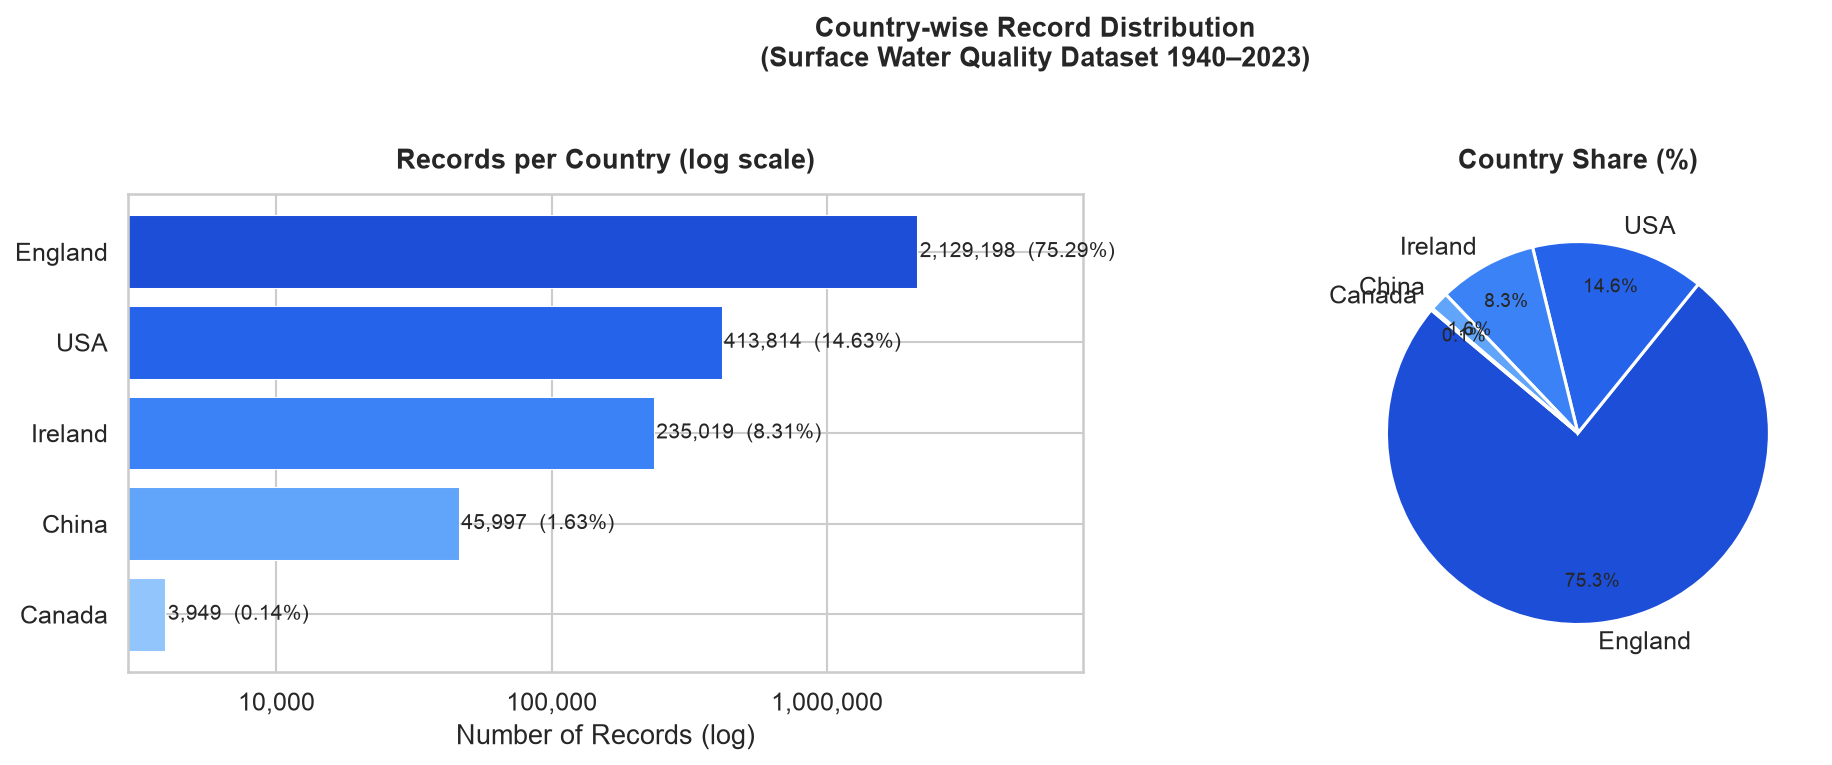

Saved → figures/01_country_distribution.png


In [3]:
country_counts = df['Country'].value_counts()
country_pcts   = (country_counts / len(df) * 100).round(2)

PALETTE = ['#1d4ed8','#2563eb','#3b82f6','#60a5fa','#93c5fd']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].barh(country_counts.index[::-1], country_counts.values[::-1],
                    color=PALETTE[::-1], edgecolor='white', linewidth=0.5)
for bar, val, pct in zip(bars, country_counts.values[::-1], country_pcts.values[::-1]):
    axes[0].text(bar.get_width() * 1.02, bar.get_y() + bar.get_height()/2,
                 f'{val:,}  ({pct}%)', va='center', fontsize=10)
axes[0].set_xscale('log')
axes[0].set_title('Records per Country (log scale)', fontweight='bold', pad=12)
axes[0].set_xlabel('Number of Records (log)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{int(x):,}'))
axes[0].set_xlim(right=country_counts.max() * 4)

# Pie chart
wedges, texts, autotexts = axes[1].pie(
    country_counts.values, labels=country_counts.index,
    autopct='%1.1f%%', colors=PALETTE,
    startangle=140, pctdistance=0.78,
    wedgeprops=dict(edgecolor='white', linewidth=1.5))
for at in autotexts: at.set_fontsize(9)
axes[1].set_title('Country Share (%)', fontweight='bold', pad=12)

plt.suptitle('Country-wise Record Distribution\n(Surface Water Quality Dataset 1940–2023)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '01_country_distribution.png'))
plt.show()
print('Saved → figures/01_country_distribution.png')

## 4. Waterbody Type Distribution

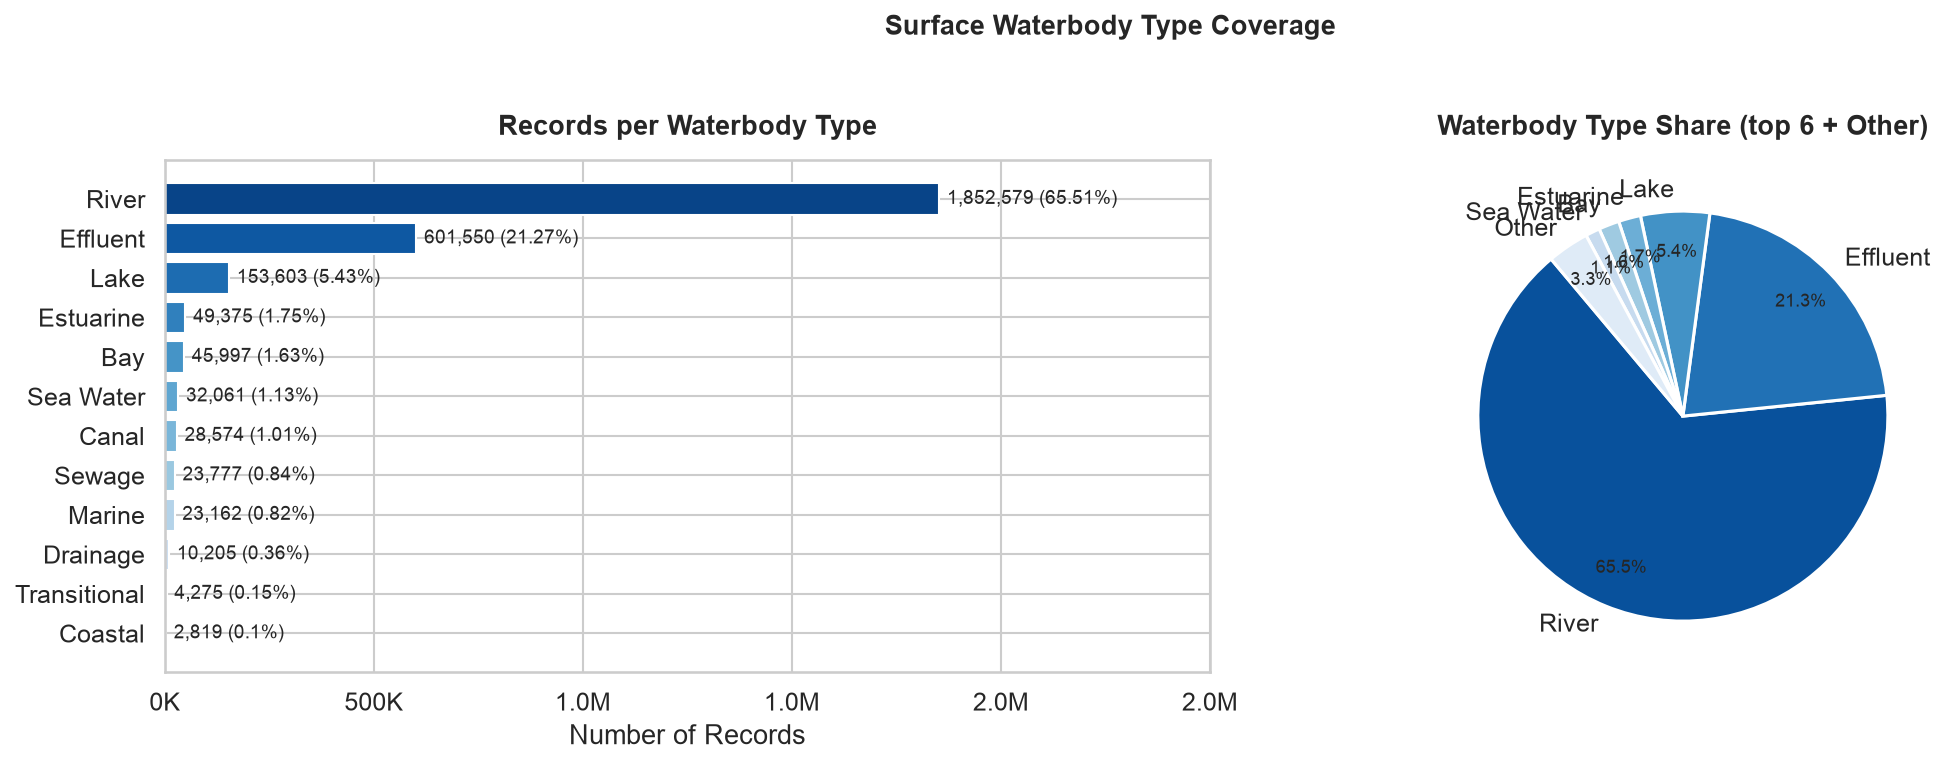

Saved → figures/02_waterbody_distribution.png


In [4]:
wb_counts = df['Waterbody Type'].value_counts()
wb_pcts   = (wb_counts / len(df) * 100).round(2)

colors = sns.color_palette('Blues_r', len(wb_counts))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars = axes[0].barh(wb_counts.index[::-1], wb_counts.values[::-1],
                    color=colors[::-1], edgecolor='white')
for bar, val, pct in zip(bars, wb_counts.values[::-1], wb_pcts.values[::-1]):
    axes[0].text(bar.get_width() + wb_counts.max()*0.01, bar.get_y() + bar.get_height()/2,
                 f'{val:,} ({pct}%)', va='center', fontsize=9)
axes[0].set_title('Records per Waterbody Type', fontweight='bold', pad=12)
axes[0].set_xlabel('Number of Records')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{int(x/1e6):.1f}M' if x>=1e6 else f'{int(x/1e3)}K'))
axes[0].set_xlim(right=wb_counts.max() * 1.35)

# Pie (top 6 + other)
top6 = wb_counts.head(6)
other = wb_counts[6:].sum()
pie_vals = pd.concat([top6, pd.Series({'Other': other})])
wedges, texts, autotexts = axes[1].pie(
    pie_vals.values, labels=pie_vals.index,
    autopct='%1.1f%%', colors=sns.color_palette('Blues_r', 7),
    startangle=130, pctdistance=0.80,
    wedgeprops=dict(edgecolor='white', linewidth=1.5))
for at in autotexts: at.set_fontsize(8.5)
axes[1].set_title('Waterbody Type Share (top 6 + Other)', fontweight='bold', pad=12)

plt.suptitle('Surface Waterbody Type Coverage', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '02_waterbody_distribution.png'))
plt.show()
print('Saved → figures/02_waterbody_distribution.png')

## 5. Temporal Coverage (1940–2023)

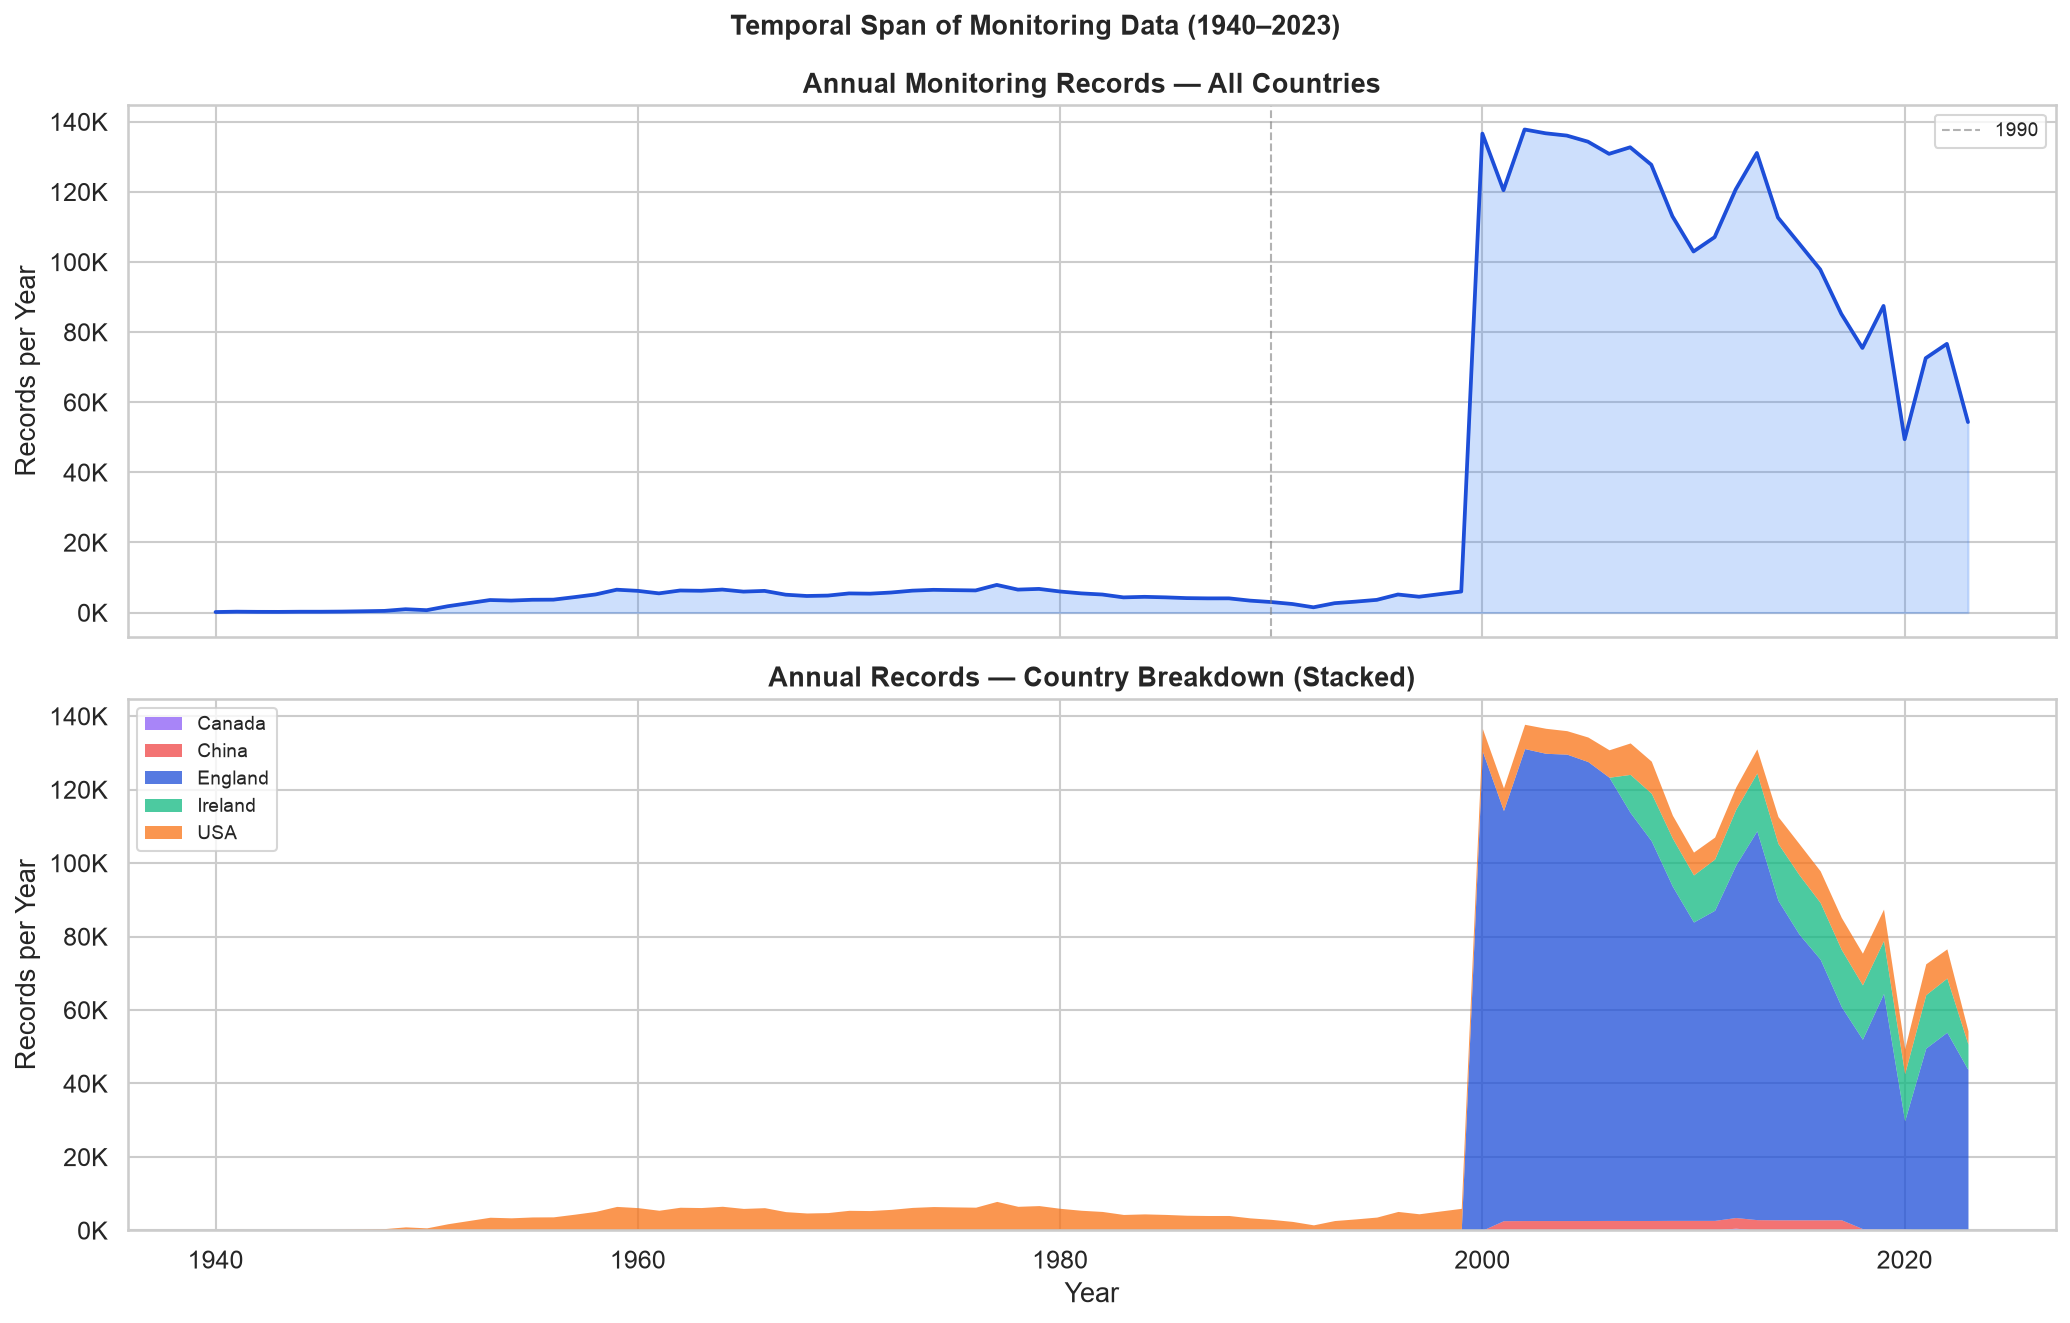

Saved → figures/03_temporal_coverage.png


In [5]:
df['Year'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce').dt.year
year_counts = df['Year'].value_counts().sort_index().dropna()

# Also per country
year_country = df.groupby(['Year', 'Country']).size().unstack(fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Total
axes[0].fill_between(year_counts.index, year_counts.values, color='#3b82f6', alpha=0.25)
axes[0].plot(year_counts.index, year_counts.values, color='#1d4ed8', lw=1.8)
axes[0].set_title('Annual Monitoring Records — All Countries', fontweight='bold')
axes[0].set_ylabel('Records per Year')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{int(x/1e3)}K'))
axes[0].axvline(1990, color='gray', ls='--', lw=1, alpha=0.6, label='1990')
axes[0].legend(fontsize=9)

# Per country stacked
country_colors = {'England':'#1d4ed8','USA':'#f97316','Ireland':'#10b981',
                  'China':'#ef4444','Canada':'#8b5cf6'}
year_country.plot.area(ax=axes[1], color=[country_colors.get(c,'gray') for c in year_country.columns],
                       alpha=0.75, linewidth=0)
axes[1].set_title('Annual Records — Country Breakdown (Stacked)', fontweight='bold')
axes[1].set_ylabel('Records per Year')
axes[1].set_xlabel('Year')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{int(x/1e3)}K'))
axes[1].legend(loc='upper left', fontsize=9)

plt.suptitle('Temporal Span of Monitoring Data (1940–2023)', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '03_temporal_coverage.png'))
plt.show()
print('Saved → figures/03_temporal_coverage.png')

## 6. Data Completeness Audit

In [6]:
# --- Null check ---
print('=' * 55)
print('NULL VALUE SUMMARY')
print('=' * 55)
null_summary = pd.DataFrame({
    'Column': df.columns,
    'Null Count': df.isnull().sum().values,
    'Null %': (df.isnull().sum() / len(df) * 100).round(4).values
})
print(null_summary.to_string(index=False))
print()
print(f'Total nulls across all columns: {df.isnull().sum().sum()}')
print('→ Dataset is COMPLETE. No imputation needed.')

print()
print('=' * 55)
print('PHYSICAL OUTLIER (IMPOSSIBLE VALUE) COUNTS')
print('=' * 55)
physical_checks = {
    'pH outside [3, 12]': ((df['pH (ph units)'] < 3) | (df['pH (ph units)'] > 12)).sum(),
    'Temperature outside [0,45]°C': ((df['Temperature (cel)'] < 0) | (df['Temperature (cel)'] > 45)).sum(),
    'DO outside [0, 25] mg/l': ((df['Dissolved Oxygen (mg/l)'] < 0) | (df['Dissolved Oxygen (mg/l)'] > 25)).sum(),
    'Ammonia < 0': (df['Ammonia (mg/l)'] < 0).sum(),
    'BOD < 0': (df['Biochemical Oxygen Demand (mg/l)'] < 0).sum(),
    'Orthophosphate < 0': (df['Orthophosphate (mg/l)'] < 0).sum(),
    'Nitrogen < 0': (df['Nitrogen (mg/l)'] < 0).sum(),
    'Nitrate < 0': (df['Nitrate (mg/l)'] < 0).sum(),
}
for check, count in physical_checks.items():
    pct = count / len(df) * 100
    print(f'  {check:<40} {count:>6,}  ({pct:.3f}%)')

# Exact union of all physical violations
invalid_union_mask = (
    (df['pH (ph units)'] < 3) | (df['pH (ph units)'] > 12) |
    (df['Temperature (cel)'] < 0) | (df['Temperature (cel)'] > 45) |
    (df['Dissolved Oxygen (mg/l)'] < 0) | (df['Dissolved Oxygen (mg/l)'] > 25) |
    (df['Ammonia (mg/l)'] < 0) |
    (df['Biochemical Oxygen Demand (mg/l)'] < 0) |
    (df['Orthophosphate (mg/l)'] < 0) |
    (df['Nitrogen (mg/l)'] < 0) |
    (df['Nitrate (mg/l)'] < 0)
)
total_invalid = int(invalid_union_mask.sum())
pct_invalid = total_invalid / len(df) * 100
print()
print(f'  Total unique physically impossible rows (union): {total_invalid:,}  ({pct_invalid:.3f}%)')
print(f'  Clean rows remaining:                           {len(df) - total_invalid:,}  ({100 - pct_invalid:.3f}%)')
print(f'  → Only {pct_invalid:.3f}% of data removed in EDA cleaning step.')


NULL VALUE SUMMARY
                          Column  Null Count  Null %
                         Country           0     0.0
                            Area           0     0.0
                  Waterbody Type           0     0.0
                            Date           0     0.0
                  Ammonia (mg/l)           0     0.0
Biochemical Oxygen Demand (mg/l)           0     0.0
         Dissolved Oxygen (mg/l)           0     0.0
           Orthophosphate (mg/l)           0     0.0
                   pH (ph units)           0     0.0
               Temperature (cel)           0     0.0
                 Nitrogen (mg/l)           0     0.0
                  Nitrate (mg/l)           0     0.0
                     CCME_Values           0     0.0
                        CCME_WQI           0     0.0
                            Year           0     0.0

Total nulls across all columns: 0
→ Dataset is COMPLETE. No imputation needed.

PHYSICAL OUTLIER (IMPOSSIBLE VALUE) COUNTS
  pH outs

## 7. Descriptive Statistics — All 8 Chemical Parameters

In [7]:
stats = df[chemical_cols].describe().round(3)
stats.loc['skew'] = df[chemical_cols].skew().round(3)
stats.loc['kurt'] = df[chemical_cols].kurtosis().round(3)
print('Descriptive Statistics (all 2,827,977 rows):')
display(stats)

Descriptive Statistics (all 2,827,977 rows):


,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l)
count,2827977.000,2827977.000,2827977.000,2827977.000,2827977.000,2827977.000,2827977.000,2827977.000
mean,1.171,4.887,10.008,0.710,7.736,11.839,5.210,4.767
std,5.669,16.414,1.851,2.089,0.495,5.010,6.200,6.074
min,-0.005,-2.000,0.000,-0.004,-1.000,-5.260,0.000,0.000
25%,0.030,1.600,9.860,0.040,7.550,8.990,0.780,1.173
50%,0.055,2.700,10.200,0.107,7.780,11.460,4.000,4.500
75%,0.317,2.830,11.000,0.227,8.000,14.200,6.320,4.940
max,200.000,255.000,20.000,100.000,30.000,98.000,46.000,155.000
skew,12.004,10.232,-1.465,8.953,3.108,3.112,2.394,6.242
kurt,222.416,117.784,4.586,206.226,162.044,30.199,7.228,82.473


## 8. Distribution of Chemical Parameters (Box Plots)

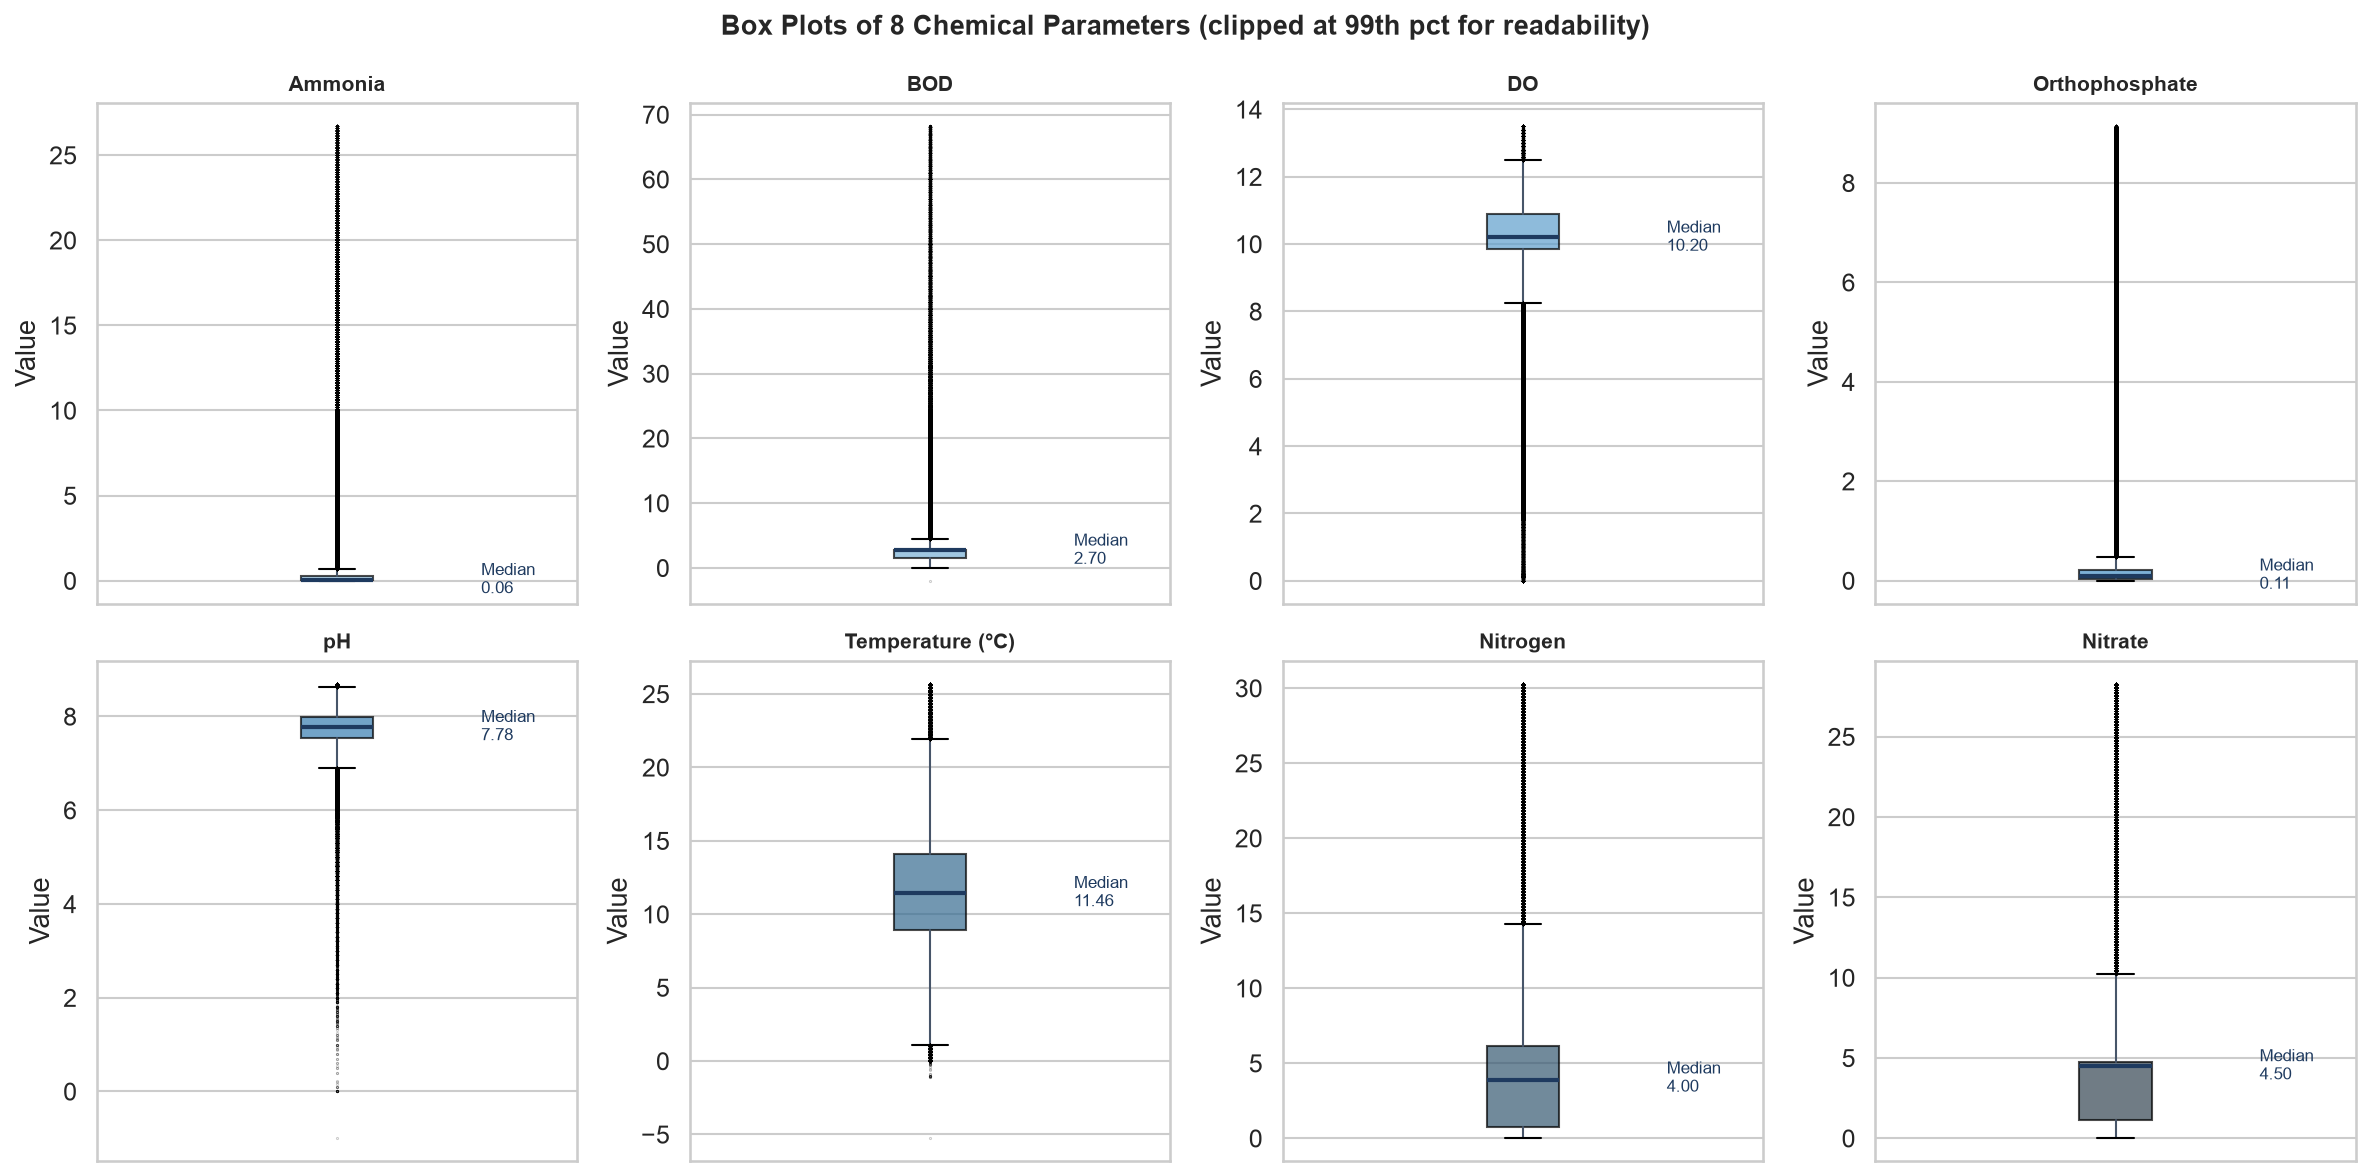

Saved → figures/04_chemical_boxplots.png


In [8]:
short_names = {
    'Ammonia (mg/l)'                    : 'Ammonia',
    'Biochemical Oxygen Demand (mg/l)'  : 'BOD',
    'Dissolved Oxygen (mg/l)'           : 'DO',
    'Orthophosphate (mg/l)'             : 'Orthophosphate',
    'pH (ph units)'                     : 'pH',
    'Temperature (cel)'                 : 'Temperature (°C)',
    'Nitrogen (mg/l)'                   : 'Nitrogen',
    'Nitrate (mg/l)'                    : 'Nitrate'
}
df_plot = df[chemical_cols].rename(columns=short_names)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
colors = sns.color_palette('Blues_d', 8)

for i, col in enumerate(df_plot.columns):
    data = df_plot[col].dropna()
    # Clip to 99th pct for readability
    p99 = data.quantile(0.99)
    data_clipped = data[data <= p99]
    axes[i].boxplot(data_clipped, patch_artist=True,
                    boxprops=dict(facecolor=colors[i], alpha=0.7),
                    medianprops=dict(color='#1e3a5f', linewidth=2),
                    whiskerprops=dict(color='#475569'),
                    flierprops=dict(marker='.', markersize=1, alpha=0.2, color='gray'))
    axes[i].set_title(col, fontweight='bold', fontsize=10)
    axes[i].set_ylabel('Value')
    axes[i].set_xticks([])
    med = float(data.median())
    axes[i].text(1.3, med, f'Median\n{med:.2f}', va='center', fontsize=8, color='#1e3a5f')

plt.suptitle('Box Plots of 8 Chemical Parameters (clipped at 99th pct for readability)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '04_chemical_boxplots.png'))
plt.show()
print('Saved → figures/04_chemical_boxplots.png')

## 9. Distribution Histograms with KDE

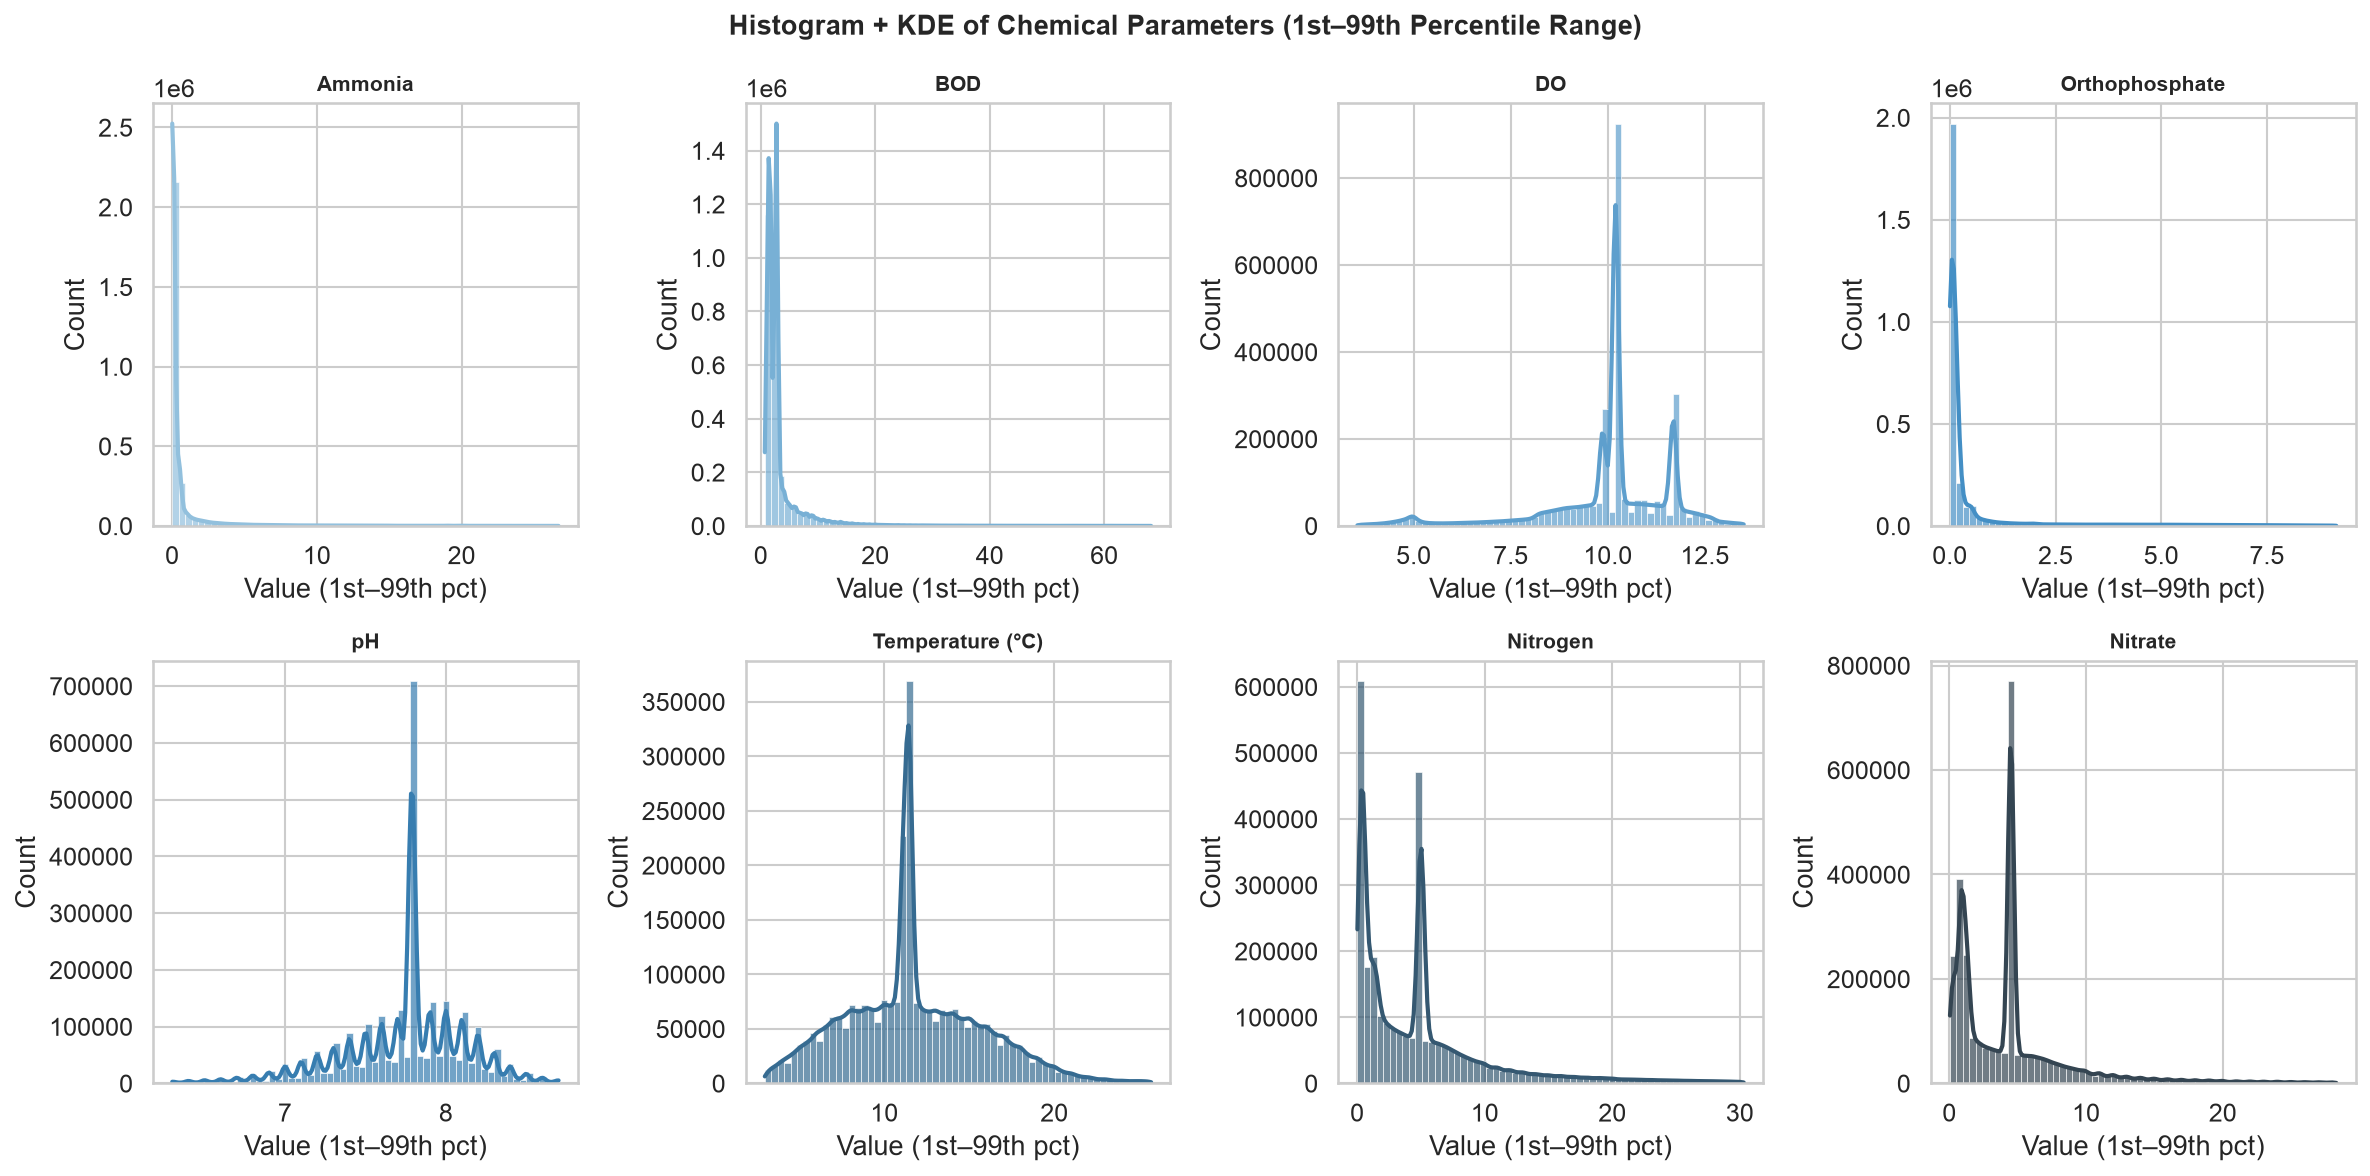

Saved → figures/05_chemical_histograms.png


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
colors_hist = sns.color_palette('Blues_d', 8)

for i, (col, short) in enumerate(short_names.items()):
    data = df[col].dropna()
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data_clipped = data[(data >= p1) & (data <= p99)]
    sns.histplot(data_clipped, ax=axes[i], kde=True, bins=60,
                 color=colors_hist[i], alpha=0.7, line_kws={'lw': 2})
    axes[i].set_title(short, fontweight='bold', fontsize=10)
    axes[i].set_xlabel('Value (1st–99th pct)')
    axes[i].set_ylabel('Count')

plt.suptitle('Histogram + KDE of Chemical Parameters (1st–99th Percentile Range)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '05_chemical_histograms.png'))
plt.show()
print('Saved → figures/05_chemical_histograms.png')

## 10. Country-wise Median Parameter Values

Median values per country:


,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l)
Country,,,,,,,,
Canada,0.100,2.133,9.824,0.061,7.79,12.00,0.400,5.837
China,0.046,0.700,7.600,0.011,8.00,24.20,0.019,0.077
England,0.098,2.700,10.200,0.144,7.78,11.46,5.000,4.500
Ireland,0.038,1.400,9.090,0.025,7.80,11.15,1.422,1.300
USA,0.021,1.600,9.870,0.040,7.80,11.10,0.400,0.900


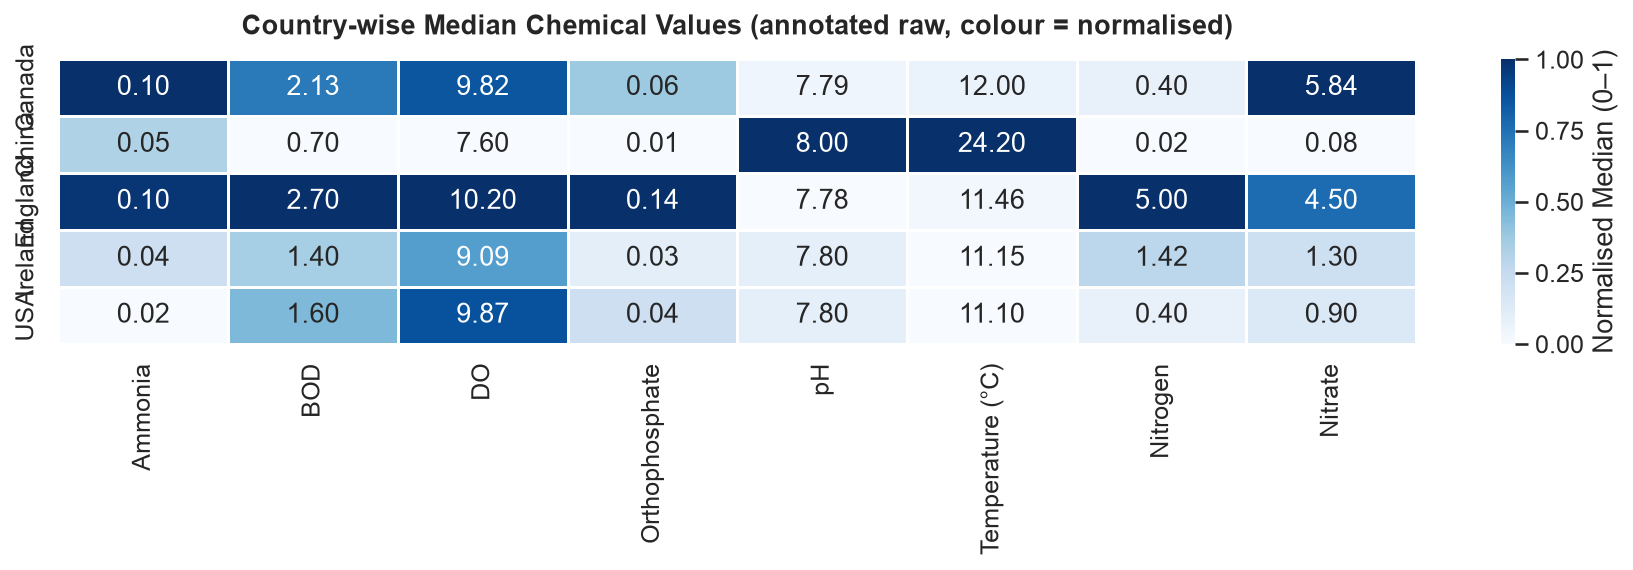

Saved → figures/06_country_median_heatmap.png


In [10]:
country_medians = df.groupby('Country')[chemical_cols].median().round(3)
print('Median values per country:')
display(country_medians)

# Heatmap
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
norm = pd.DataFrame(scaler.fit_transform(country_medians),
                    index=country_medians.index,
                    columns=[short_names[c] for c in country_medians.columns])

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(norm, annot=country_medians.rename(columns=short_names).values,
            fmt='.2f', cmap='Blues', linewidths=0.5,
            cbar_kws={'label': 'Normalised Median (0–1)'}, ax=ax)
ax.set_title('Country-wise Median Chemical Values (annotated raw, colour = normalised)',
             fontweight='bold', pad=12)
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '06_country_median_heatmap.png'))
plt.show()
print('Saved → figures/06_country_median_heatmap.png')

## Summary

| Metric | Value |
|---|
| Total raw rows | 2,827,977 |
| Total columns | 14 |
| Null values | **0** (dataset fully complete) |
| Countries | 5 (England, USA, Ireland, China, Canada) |
| Waterbody types | 12 (River, Effluent, Lake, Estuarine, Bay, …) |
| Date range | 1940 – 2023 |
| Chemical parameters | 8 |
| Physically impossible rows | 8,360 (0.296%) — removed in cleaning step (2,819,617 clean rows remaining) |

**Next:** `02_data_patterns_and_target.ipynb` — correlations, seasonal patterns, outlier validation, and export of cleaned dataset.
